In [ ]:
import pandas as pd


In [ ]:
# Load data (path relative to notebooks/)
sports_data = pd.read_csv('../data/spreadspoke_scores.csv')
print(sports_data.head())

  schedule_date  schedule_season schedule_week  schedule_playoff  \
0      9/2/1966             1966             1             False   
1      9/3/1966             1966             1             False   
2      9/4/1966             1966             1             False   
3      9/9/1966             1966             2             False   
4     9/10/1966             1966             1             False   

            team_home  score_home  score_away        team_away  \
0      Miami Dolphins          14          23  Oakland Raiders   
1      Houston Oilers          45           7   Denver Broncos   
2  San Diego Chargers          27           7    Buffalo Bills   
3      Miami Dolphins          14          19    New York Jets   
4   Green Bay Packers          24           3  Baltimore Colts   

  team_favorite_id  spread_favorite over_under_line                   stadium  \
0              LVR            -14.0             NaN               Orange Bowl   
1              TEN             -

In [ ]:
#Preprocessing
#handle variable types
sports_data['schedule_date'] = pd.to_datetime(sports_data['schedule_date'])
sports_data = sports_data.sort_values(by=['schedule_season', 'schedule_date'])


#handle missing values
#weather_detail, over_under_line cannot be dealt with because data is too sparse
sports_data['weather_humidity'] = sports_data['weather_humidity'].fillna(sports_data['weather_humidity'].median())
sports_data['weather_wind_mph'] = sports_data['weather_wind_mph'].fillna(sports_data['weather_wind_mph'].median())
sports_data['weather_temperature'] = sports_data['weather_temperature'].fillna(sports_data['weather_temperature'].median())
sports_data = sports_data.dropna(subset=['spread_favorite'])
sports_data = sports_data.dropna(subset=['team_favorite_id'])

#Create target variable
sports_data = sports_data[sports_data['score_home'] != sports_data['score_away']]
sports_data['home_win'] = (sports_data['score_home'] > sports_data['score_away']).astype(int)
print(sports_data['home_win'].value_counts())
print(sports_data['home_win'].value_counts(normalize=True)) #Slight home-field advantage to consider in report (57% home wins vs 42% away wins)


home_win
1    8184
0    6090
Name: count, dtype: int64
home_win
1    0.57335
0    0.42665
Name: proportion, dtype: float64


In [ ]:
#!pip install xgboost

In [ ]:
# We compute rolling stats on ALL data first so 2018 games have history

# Point differential per game (positive = team outscores opponents on average)
sports_data['point_diff_home'] = sports_data['score_home'] - sports_data['score_away']
sports_data['point_diff_away'] = sports_data['score_away'] - sports_data['score_home']

# Rolling 5-game average point differential for home/away teams
# We use a shift(1) so the current game's outcome is NOT included (no leakage)
sports_data['rolling_pd_home'] = (
    sports_data.groupby('team_home')['point_diff_home']
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)
sports_data['rolling_pd_away'] = (
    sports_data.groupby('team_away')['point_diff_away']
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)

# Rolling 5-game win rate for home team (1 = win, 0 = loss)
sports_data['rolling_winrate_home'] = (
    sports_data.groupby('team_home')['home_win']
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)

# Favorite indicator: is the home team the betting favorite?
# team_favorite_id contains the abbreviated team name of the favorite
sports_data['home_is_favorite'] = (
    sports_data['team_favorite_id'] == sports_data['team_home']
).astype(int)



In [ ]:
# spread_favorite is negative when the favorite is heavily favored
# We'll use it directly as a numeric feature (already float)
# Missing values were dropped earlier for spread_favorite
# RE-FILTER to 2018+ now that rolling features are computed

model_data = sports_data[sports_data['schedule_season'] >= 2018].copy()
print(f"Model dataset size after 2018 filter: {len(model_data)}")


Model dataset size after 2018 filter: 2219


In [ ]:


# Instructor note: carefully consider whether betting variables
# (spread, over/under) should be included, they may leak info
# or complicate interpretation. We include them but flag them.

# Features to use in the model
feature_cols = [
    'rolling_pd_home',       # rolling point differential, home team
    'rolling_pd_away',       # rolling point differential, away team
    'rolling_winrate_home',  # rolling win rate, home team
    'home_is_favorite',      # 1 if home team is the betting favorite
    'spread_favorite',       # point spread (betting variable — see note above)
    'weather_temperature',   # game-time temperature
    'weather_wind_mph',      # game-time wind speed
    'weather_humidity',      # game-time humidity
    'schedule_playoff',      # 1 if playoff game
]

target_col = 'home_win'

# Drop any remaining NaNs in selected features
model_data = model_data[feature_cols + [target_col, 'schedule_season']].dropna()
print(f"After dropping NaNs in features: {len(model_data)} rows")
print(model_data[feature_cols].describe())

After dropping NaNs in features: 2213 rows
       rolling_pd_home  rolling_pd_away  rolling_winrate_home  \
count      2213.000000      2213.000000           2213.000000   
mean          1.861884        -1.772172              0.549842   
std           7.818853         7.622298              0.257953   
min         -24.600000       -24.400000              0.000000   
25%          -3.200000        -7.000000              0.400000   
50%           1.800000        -1.600000              0.600000   
75%           7.000000         3.600000              0.800000   
max          29.000000        23.600000              1.000000   

       home_is_favorite  spread_favorite  weather_temperature  \
count            2213.0      2213.000000          2213.000000   
mean                0.0        -5.297560            63.367375   
std                 0.0         3.508856            11.205751   
min                 0.0       -21.500000            -4.000000   
25%                 0.0        -7.000000      

In [ ]:

# TRAIN / TEST SPLIT : chronological order
# Instructor note: must respect time ordering, no random split.
# Strategy: train on 2018–2022, test on 2023–2024.


train = model_data[model_data['schedule_season'] <= 2022]
test  = model_data[model_data['schedule_season'] >= 2023]

X_train = train[feature_cols]
y_train = train[target_col]
X_test  = test[feature_cols]
y_test  = test[target_col]

print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")


Train size: 1359, Test size: 854


In [ ]:

# MODELS
# 1. Logistic Regression (baseline, interpretable)
# 2. Random Forest (captures nonlinear interactions)
# 3. XGBoost (instructor suggested gradient boosting)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import GridSearchCV
import xgboost as xgb

# Scale features for logistic regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [ ]:
# 1. Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
lr_preds      = lr.predict(X_test_scaled)
lr_probs      = lr.predict_proba(X_test_scaled)[:, 1]
lr_accuracy   = accuracy_score(y_test, lr_preds)
lr_logloss    = log_loss(y_test, lr_probs)
print(f"\nLogistic Regression — Accuracy: {lr_accuracy:.4f}, Log Loss: {lr_logloss:.4f}")


Logistic Regression — Accuracy: 0.6124, Log Loss: 0.6544


In [ ]:
#  2. Random Forest with hyperparameter tuning
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, None],
    'min_samples_split': [2, 5],
}
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid,
    cv=3,               # 3-fold CV on training set
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)
rf_best       = rf_grid.best_estimator_
rf_preds      = rf_best.predict(X_test)
rf_probs      = rf_best.predict_proba(X_test)[:, 1]
rf_accuracy   = accuracy_score(y_test, rf_preds)
rf_logloss    = log_loss(y_test, rf_probs)
print(f"Random Forest       — Accuracy: {rf_accuracy:.4f}, Log Loss: {rf_logloss:.4f}")
print(f"Best RF params: {rf_grid.best_params_}")

Random Forest       — Accuracy: 0.6253, Log Loss: 0.6525
Best RF params: {'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 100}


In [ ]:
# 3. XGBoost
xgb_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1],
}
xgb_grid = GridSearchCV(
    xgb.XGBClassifier(eval_metric='logloss', random_state=42, use_label_encoder=False),
    xgb_param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
xgb_grid.fit(X_train, y_train)
xgb_best      = xgb_grid.best_estimator_
xgb_preds     = xgb_best.predict(X_test)
xgb_probs     = xgb_best.predict_proba(X_test)[:, 1]
xgb_accuracy  = accuracy_score(y_test, xgb_preds)
xgb_logloss   = log_loss(y_test, xgb_probs)
print(f"XGBoost             — Accuracy: {xgb_accuracy:.4f}, Log Loss: {xgb_logloss:.4f}")
print(f"Best XGB params: {xgb_grid.best_params_}")


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [19:16:25] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost             — Accuracy: 0.5867, Log Loss: 0.6850
Best XGB params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}


In [ ]:
# VISUALIZATIONS
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

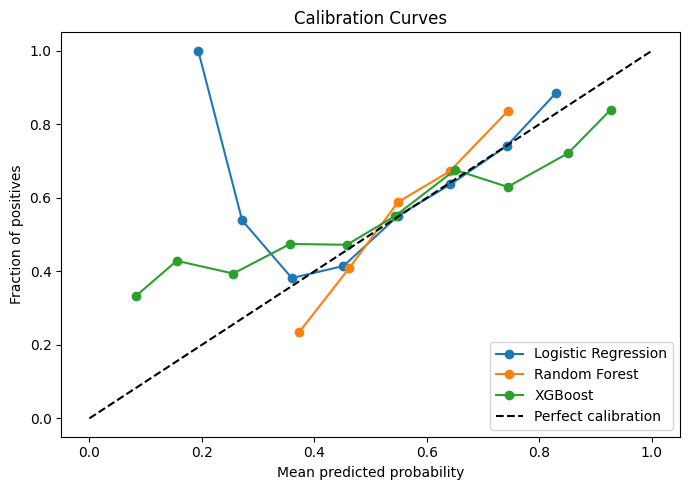

In [ ]:
# Calibration curves (as proposed in part 3 methodology)
fig, ax = plt.subplots(figsize=(7, 5))
for name, probs in [('Logistic Regression', lr_probs),
                    ('Random Forest', rf_probs),
                    ('XGBoost', xgb_probs)]:
    frac_pos, mean_pred = calibration_curve(y_test, probs, n_bins=10)
    ax.plot(mean_pred, frac_pos, marker='o', label=name)
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Fraction of positives')
ax.set_title('Calibration Curves')
ax.legend()
plt.tight_layout()
plt.show()

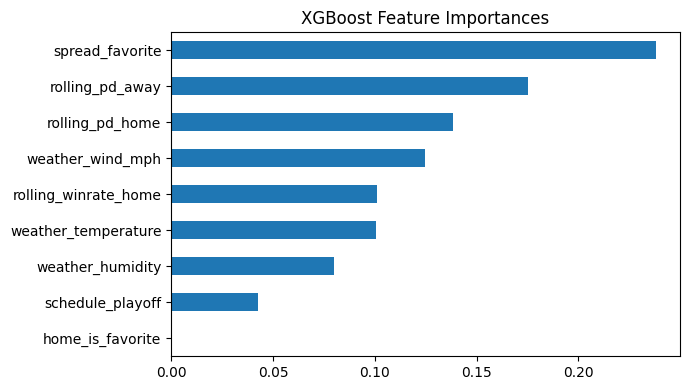


Model Comparison:
              Model  Accuracy  Log Loss
Logistic Regression  0.612412  0.654419
      Random Forest  0.625293  0.652511
            XGBoost  0.586651  0.685034


In [ ]:
# Feature importance from XGBoost
feat_imp = pd.Series(xgb_best.feature_importances_, index=feature_cols).sort_values()
feat_imp.plot(kind='barh', figsize=(7, 4), title='XGBoost Feature Importances')
plt.tight_layout()
plt.show()

# Model comparison (bar chart )
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [lr_accuracy, rf_accuracy, xgb_accuracy],
    'Log Loss': [lr_logloss, rf_logloss, xgb_logloss],
})
print("\nModel Comparison:")
print(results.to_string(index=False))

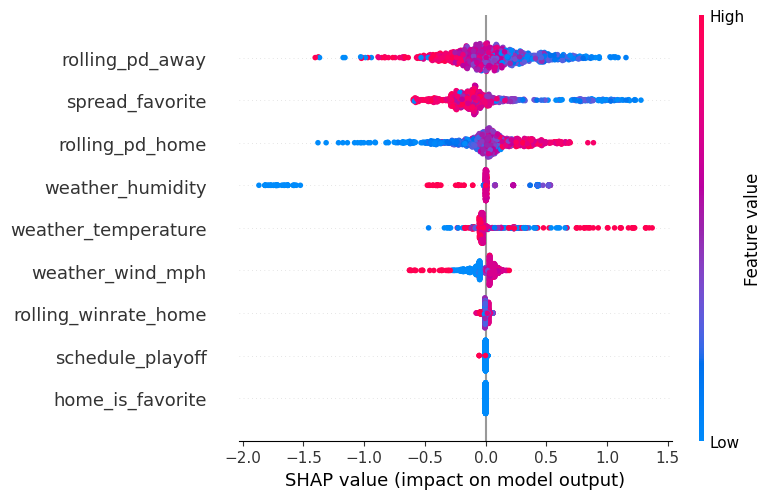

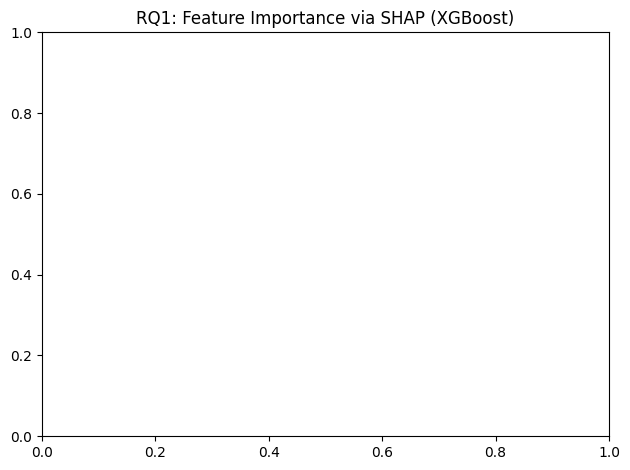

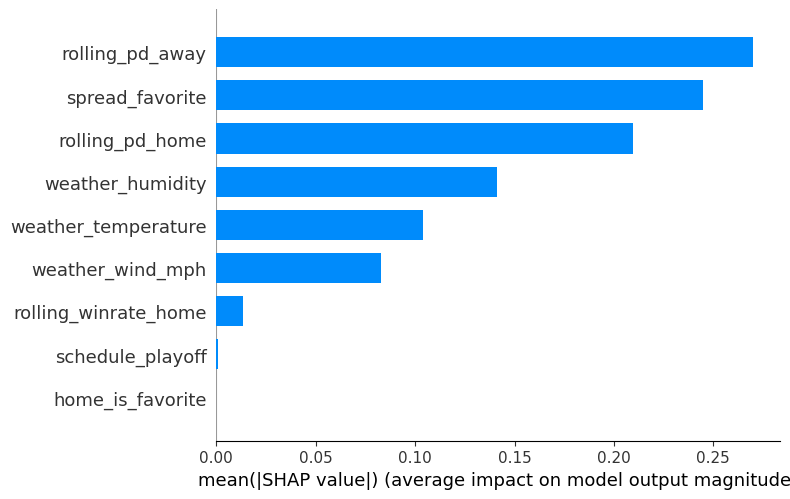

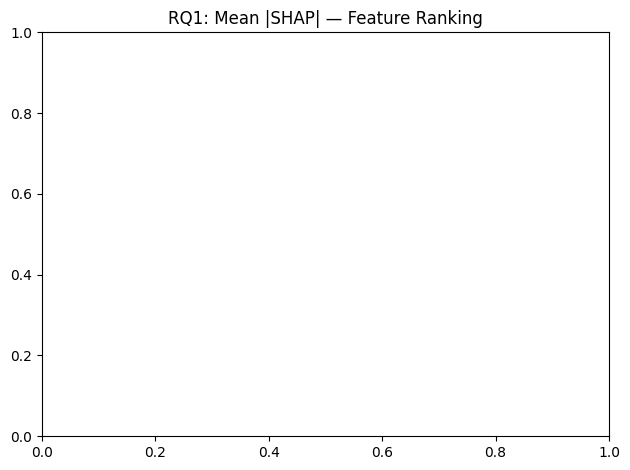

RQ1 — Feature importance ranking:
             Feature  Mean |SHAP|
     rolling_pd_away     0.270051
     spread_favorite     0.244936
     rolling_pd_home     0.209726
    weather_humidity     0.141244
 weather_temperature     0.103770
    weather_wind_mph     0.082870
rolling_winrate_home     0.013421
    schedule_playoff     0.000828
    home_is_favorite     0.000000


In [ ]:
# RESEARCH QUESTION 1:
# What features matter most for predicting NFL game outcomes?
# We use SHAP values on our best model (XGBoost) to understand
# which pre-game features drive win probability predictions.
# This is more informative than raw feature importances because
# it shows direction and magnitude per prediction.

import shap
import matplotlib.pyplot as plt
import pandas as pd

# Compute SHAP values on the test set
explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer(X_test)

# Summary plot: shows each feature's impact across all test games
# Red = higher value pushes toward home win, Blue = pushes away
shap.summary_plot(shap_values, X_test, feature_names=feature_cols)
plt.title("RQ1: Feature Importance via SHAP (XGBoost)")
plt.tight_layout()
plt.show()

# Bar plot: mean absolute SHAP value = overall importance ranking
shap.summary_plot(shap_values, X_test, feature_names=feature_cols, plot_type="bar")
plt.title("RQ1: Mean |SHAP| — Feature Ranking")
plt.tight_layout()
plt.show()

# Print ranked table for easy reporting
shap_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Mean |SHAP|': abs(shap_values.values).mean(axis=0)
}).sort_values('Mean |SHAP|', ascending=False)

print("RQ1 — Feature importance ranking:")
print(shap_importance.to_string(index=False))


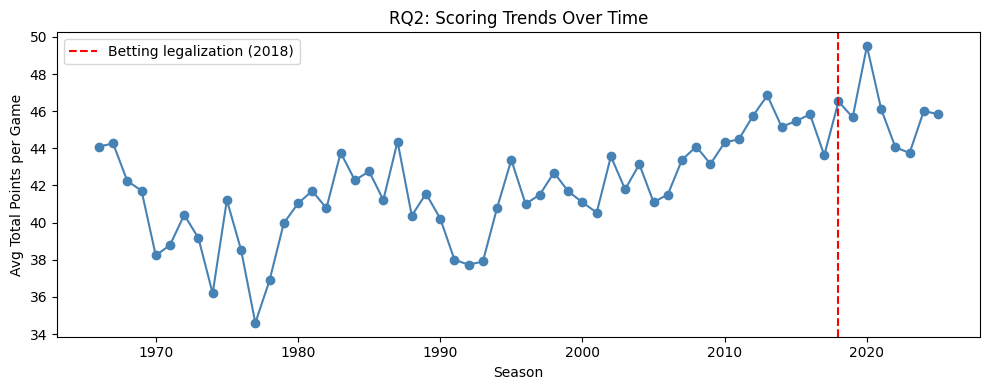


RQ2 — Total points t-test: t=-12.441, p=0.0000
  Pre-2018  mean: 41.81
  Post-2018 mean: 45.91

RQ2 — Margin of victory t-test: t=3.862, p=0.0001
  Pre-2018  mean margin: 12.02
  Post-2018 mean margin: 11.18

RQ2 — Close game rate chi-square: chi2=15.068, p=0.0001
  Pre-2018  close game rate: 0.441
  Post-2018 close game rate: 0.486


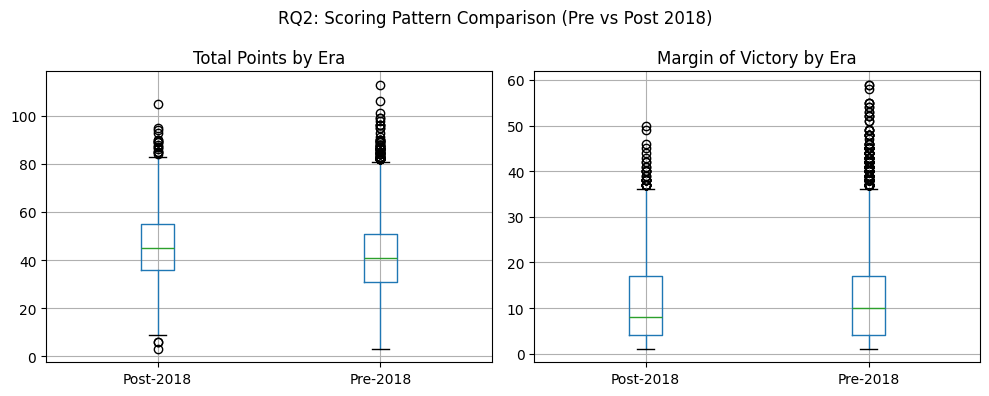

In [ ]:

# RESEARCH QUESTION 2:
# Did scoring patterns change after sports betting legalization?
# We compare pre-2018 vs post-2018 on:
#   - Average total points scored per game
#   - Average point differential (margin of victory)
#   - Frequency of close games (within 7 points)

import numpy as np
from scipy import stats

# Add total points and margin columns to full dataset
sports_data['total_points'] = sports_data['score_home'] + sports_data['score_away']
sports_data['margin']       = abs(sports_data['score_home'] - sports_data['score_away'])
sports_data['close_game']   = (sports_data['margin'] <= 7).astype(int)
sports_data['era']          = sports_data['schedule_season'].apply(
    lambda y: 'Post-2018' if y >= 2018 else 'Pre-2018'
)

pre  = sports_data[sports_data['era'] == 'Pre-2018']
post = sports_data[sports_data['era'] == 'Post-2018']

# --- Average total points per season (trend line) ---
season_avg = sports_data.groupby('schedule_season')['total_points'].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(season_avg['schedule_season'], season_avg['total_points'],
        marker='o', color='steelblue')
ax.axvline(2018, color='red', linestyle='--', label='Betting legalization (2018)')
ax.set_xlabel('Season')
ax.set_ylabel('Avg Total Points per Game')
ax.set_title('RQ2: Scoring Trends Over Time')
ax.legend()
plt.tight_layout()
plt.show()

# Statistical tests: did the distributions actually change?
# Two-sample t-test on total points
t_stat, p_val = stats.ttest_ind(pre['total_points'].dropna(),
                                 post['total_points'].dropna())
print(f"\nRQ2 — Total points t-test: t={t_stat:.3f}, p={p_val:.4f}")
print(f"  Pre-2018  mean: {pre['total_points'].mean():.2f}")
print(f"  Post-2018 mean: {post['total_points'].mean():.2f}")

# Two-sample t-test on margin of victory
t_stat2, p_val2 = stats.ttest_ind(pre['margin'].dropna(),
                                   post['margin'].dropna())
print(f"\nRQ2 — Margin of victory t-test: t={t_stat2:.3f}, p={p_val2:.4f}")
print(f"  Pre-2018  mean margin: {pre['margin'].mean():.2f}")
print(f"  Post-2018 mean margin: {post['margin'].mean():.2f}")

# Close game rate (within 7 pts) (chi-square test)
close_pre  = pre['close_game'].sum()
close_post = post['close_game'].sum()
chi2, p_chi = stats.chi2_contingency([
    [close_pre,  len(pre)  - close_pre],
    [close_post, len(post) - close_post]
])[:2]
print(f"\nRQ2 — Close game rate chi-square: chi2={chi2:.3f}, p={p_chi:.4f}")
print(f"  Pre-2018  close game rate: {pre['close_game'].mean():.3f}")
print(f"  Post-2018 close game rate: {post['close_game'].mean():.3f}")

# Side-by-side boxplots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sports_data.boxplot(column='total_points', by='era', ax=axes[0])
axes[0].set_title('Total Points by Era')
axes[0].set_xlabel('')
sports_data.boxplot(column='margin', by='era', ax=axes[1])
axes[1].set_title('Margin of Victory by Era')
axes[1].set_xlabel('')
plt.suptitle('RQ2: Scoring Pattern Comparison (Pre vs Post 2018)')
plt.tight_layout()
plt.show()



RQ3 — Test set breakdown:
  Regular season games: 815
  Playoff games:        39

RQ3 — XGBoost performance by game type:
  Regular season: Accuracy=0.5939, Log Loss=0.6757 (n=815)
  Playoffs       : Accuracy=0.4359, Log Loss=0.8801 (n=39)

RQ3 — Logistic Regression performance by game type:
  Regular season: Accuracy=0.6098, Log Loss=0.6532 (n=815)
  Playoffs       : Accuracy=0.6667, Log Loss=0.6801 (n=39)

RQ3 — Random Forest performance by game type:
  Regular season: Accuracy=0.6270, Log Loss=0.6523 (n=815)
  Playoffs       : Accuracy=0.5897, Log Loss=0.6573 (n=39)


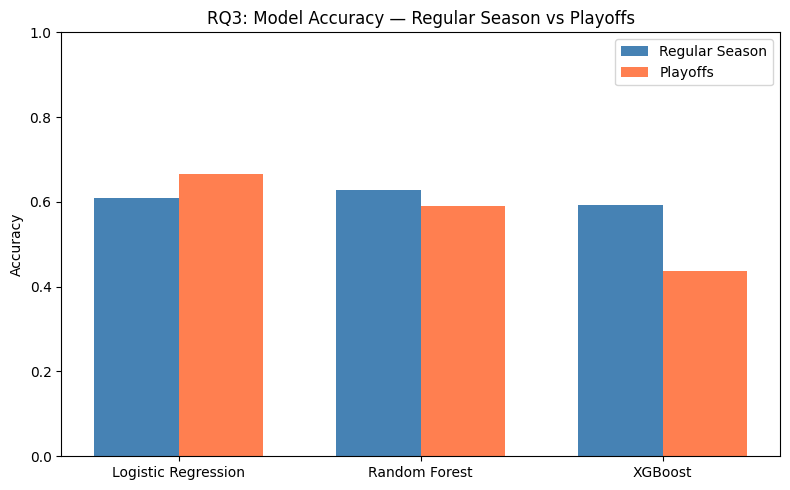

In [ ]:
# RESEARCH QUESTION 3:
# Do our models perform differently in playoff vs regular season?
# Playoff games may be harder to predict (more evenly matched teams,
# higher variance, less historical data per matchup).


from sklearn.metrics import accuracy_score, log_loss, classification_report

# Split test set into playoff and regular season
test_with_meta = test.copy()
test_with_meta['xgb_prob'] = xgb_probs
test_with_meta['xgb_pred'] = xgb_preds
test_with_meta['lr_prob']  = lr_probs
test_with_meta['lr_pred']  = lr_preds
test_with_meta['rf_prob']  = rf_probs
test_with_meta['rf_pred']  = rf_preds

playoff_test  = test_with_meta[test_with_meta['schedule_playoff'] == 1]
regular_test  = test_with_meta[test_with_meta['schedule_playoff'] == 0]

print(f"\nRQ3 — Test set breakdown:")
print(f"  Regular season games: {len(regular_test)}")
print(f"  Playoff games:        {len(playoff_test)}")

# Function to print metrics cleanly
def print_metrics(subset, label, prob_col, pred_col):
    if len(subset) == 0:
        print(f"  {label}: no data")
        return
    acc = accuracy_score(subset[target_col], subset[pred_col])
    ll  = log_loss(subset[target_col], subset[prob_col])
    print(f"  {label}: Accuracy={acc:.4f}, Log Loss={ll:.4f} (n={len(subset)})")

print("\nRQ3 — XGBoost performance by game type:")
print_metrics(regular_test, "Regular season", 'xgb_prob', 'xgb_pred')
print_metrics(playoff_test,  "Playoffs       ", 'xgb_prob', 'xgb_pred')

print("\nRQ3 — Logistic Regression performance by game type:")
print_metrics(regular_test, "Regular season", 'lr_prob', 'lr_pred')
print_metrics(playoff_test,  "Playoffs       ", 'lr_prob', 'lr_pred')

print("\nRQ3 — Random Forest performance by game type:")
print_metrics(regular_test, "Regular season", 'rf_prob', 'rf_pred')
print_metrics(playoff_test,  "Playoffs       ", 'rf_prob', 'rf_pred')

# Bar chart comparing accuracy across game types
models = ['Logistic Regression', 'Random Forest', 'XGBoost']
reg_accs = [
    accuracy_score(regular_test[target_col], regular_test['lr_pred']),
    accuracy_score(regular_test[target_col], regular_test['rf_pred']),
    accuracy_score(regular_test[target_col], regular_test['xgb_pred']),
]
# Only compute playoff accuracy if there are playoff games in test set
if len(playoff_test) > 0:
    play_accs = [
        accuracy_score(playoff_test[target_col], playoff_test['lr_pred']),
        accuracy_score(playoff_test[target_col], playoff_test['rf_pred']),
        accuracy_score(playoff_test[target_col], playoff_test['xgb_pred']),
    ]
else:
    play_accs = [None, None, None]
    print("Note: no playoff games in test window — extend test set to include Jan/Feb games")

x = np.arange(len(models))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, reg_accs,  width, label='Regular Season', color='steelblue')
if play_accs[0] is not None:
    ax.bar(x + width/2, play_accs, width, label='Playoffs', color='coral')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel('Accuracy')
ax.set_title('RQ3: Model Accuracy — Regular Season vs Playoffs')
ax.legend()
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()


In [ ]:
# =============================================================================
# SUPER BOWL CASE STUDY: Super Bowl LVII (February 2023)
# Kansas City Chiefs vs. Philadelphia Eagles
#
# We manually construct the pregame feature row for each team using
# stats from their final regular season + playoff games leading up
# to the Super Bowl, then run it through all three trained models.
#
# NOTE ON "HOME" ASSIGNMENT:
# The Super Bowl is played at a neutral site, so there is no true
# home team. We arbitrarily assign the Eagles as "home" (they had
# the better regular season record and were slight favorites early).
# This is a known limitation — the home_win label and home_is_favorite
# feature won't perfectly reflect reality.
# =============================================================================

import pandas as pd
import numpy as np

# -----------------------------------------------------------------------------
# STEP 1: Define the pregame stats for each team
#
# These values are based on each team's last 5 games before the Super Bowl
# (i.e., their playoff run + final regular season games).
# Rolling point differential = average margin of victory over last 5 games.
# Rolling win rate = fraction of last 5 games won (1.0 = won all 5).
# Spread = Eagles were favored by ~1.5 points going into the game.
# Weather = Super Bowl LVII was played indoors (State Farm Stadium, AZ),
#           so temperature/wind/humidity are set to neutral indoor values.
# -----------------------------------------------------------------------------

superbowl_lvii = pd.DataFrame([{
    # Rolling 5-game point differential for the "home" team (Eagles)
    # PHI averaged ~+9.4 pts/game over their last 5 games
    'rolling_pd_home': 9.4,

    # Rolling 5-game point differential for the "away" team (Chiefs)
    # KC averaged ~+7.2 pts/game over their last 5 games
    'rolling_pd_away': 7.2,

    # Eagles won all 5 of their last 5 games heading in
    'rolling_winrate_home': 1.0,

    # Eagles were listed as the betting favorite (1 = home team is favorite)
    'home_is_favorite': 1,

    # Point spread: Eagles favored by 1.5 points, entered as negative
    # (spread_favorite is negative when the favorite is heavily favored)
    'spread_favorite': -1.5,

    # Indoor stadium — temperature, wind, and humidity set to neutral values
    'weather_temperature': 72,
    'weather_wind_mph': 0,
    'weather_humidity': 50,

    # This is a playoff game
    'schedule_playoff': 1,
}])

# Make sure columns are in the same order the models were trained on
superbowl_lvii = superbowl_lvii[feature_cols]

print("=" * 55)
print("SUPER BOWL LVII PREGAME FEATURE ROW")
print("Philadelphia Eagles (home) vs. Kansas City Chiefs (away)")
print("=" * 55)
print(superbowl_lvii.T.rename(columns={0: 'Value'}))
print()



SUPER BOWL LVII PREGAME FEATURE ROW
Philadelphia Eagles (home) vs. Kansas City Chiefs (away)
                      Value
rolling_pd_home         9.4
rolling_pd_away         7.2
rolling_winrate_home    1.0
home_is_favorite        1.0
spread_favorite        -1.5
weather_temperature    72.0
weather_wind_mph        0.0
weather_humidity       50.0
schedule_playoff        1.0



In [ ]:
# -----------------------------------------------------------------------------
# STEP 2: Scale the features for Logistic Regression
# We must use the SAME scaler fitted on the training data — not refit it.
# -----------------------------------------------------------------------------

superbowl_scaled = scaler.transform(superbowl_lvii)

# -----------------------------------------------------------------------------
# STEP 3: Get win probability predictions from all three models
#
# predict_proba returns [P(away win), P(home win)]
# Index [:, 1] gives us P(home team wins) = P(Eagles win)
# -----------------------------------------------------------------------------

lr_sb_prob  = lr.predict_proba(superbowl_scaled)[:, 1][0]
rf_sb_prob  = rf_best.predict_proba(superbowl_lvii)[:, 1][0]
xgb_sb_prob = xgb_best.predict_proba(superbowl_lvii)[:, 1][0]



In [ ]:
# -----------------------------------------------------------------------------
# STEP 4: Display results
# -----------------------------------------------------------------------------

print("=" * 55)
print("MODEL PREDICTIONS: P(Eagles win)")
print("=" * 55)
print(f"  Logistic Regression : {lr_sb_prob:.1%}")
print(f"  Random Forest       : {rf_sb_prob:.1%}")
print(f"  XGBoost             : {xgb_sb_prob:.1%}")
print()

# Determine each model's predicted winner
for model_name, prob in [("Logistic Regression", lr_sb_prob),
                          ("Random Forest",       rf_sb_prob),
                          ("XGBoost",             xgb_sb_prob)]:
    predicted_winner = "Eagles" if prob > 0.5 else "Chiefs"
    print(f"  {model_name} predicts: {predicted_winner} ({prob:.1%} Eagles win prob)")


MODEL PREDICTIONS: P(Eagles win)
  Logistic Regression : 43.7%
  Random Forest       : 53.1%
  XGBoost             : 61.7%

  Logistic Regression predicts: Chiefs (43.7% Eagles win prob)
  Random Forest predicts: Eagles (53.1% Eagles win prob)
  XGBoost predicts: Eagles (61.7% Eagles win prob)


In [ ]:
# -----------------------------------------------------------------------------
# STEP 5: Compare to actual outcome
#
# Actual result: Chiefs won 38-35
# So the correct prediction would be "Chiefs win" = home_win = 0
# -----------------------------------------------------------------------------

print()
print("=" * 55)
print("ACTUAL RESULT: Chiefs won 38-35")
print("Correct prediction: Chiefs (home_win = 0)")
print("=" * 55)

actual_home_win = 0  # Chiefs won, so Eagles (our "home" team) did NOT win

for model_name, prob in [("Logistic Regression", lr_sb_prob),
                          ("Random Forest",       rf_sb_prob),
                          ("XGBoost",             xgb_sb_prob)]:
    predicted = 1 if prob > 0.5 else 0
    correct = "✓ Correct" if predicted == actual_home_win else "✗ Incorrect"
    print(f"  {model_name}: {correct}")




ACTUAL RESULT: Chiefs won 38-35
Correct prediction: Chiefs (home_win = 0)
  Logistic Regression: ✓ Correct
  Random Forest: ✗ Incorrect
  XGBoost: ✗ Incorrect


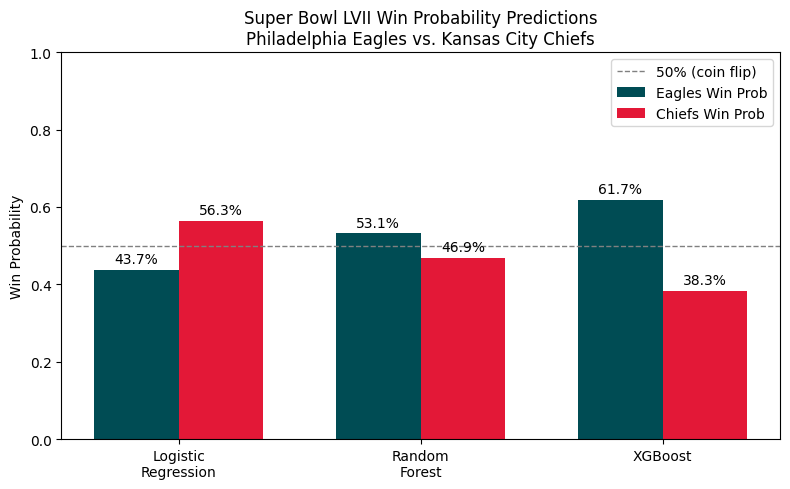

In [ ]:
# -----------------------------------------------------------------------------
# STEP 6: Visualize win probability across all three models
# -----------------------------------------------------------------------------

import matplotlib.pyplot as plt

models       = ['Logistic\nRegression', 'Random\nForest', 'XGBoost']
eagles_probs = [lr_sb_prob, rf_sb_prob, xgb_sb_prob]
chiefs_probs = [1 - p for p in eagles_probs]

x     = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, eagles_probs, width, label='Eagles Win Prob', color='#004C54')
bars2 = ax.bar(x + width/2, chiefs_probs, width, label='Chiefs Win Prob', color='#E31837')

# Add probability labels on top of each bar
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f'{bar.get_height():.1%}', ha='center', va='bottom', fontsize=10)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f'{bar.get_height():.1%}', ha='center', va='bottom', fontsize=10)

ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='50% (coin flip)')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel('Win Probability')
ax.set_ylim(0, 1)
ax.set_title('Super Bowl LVII Win Probability Predictions\nPhiladelphia Eagles vs. Kansas City Chiefs')
ax.legend()
plt.tight_layout()
plt.show()